ASSIGNMENT No: 06 
 
Title: Agricultural Genomics and Crop Improvement  
Problem Statement: 
Analyze genomic data from crops to identify genetic markers associated with desirable traits, such as disease resistance 
or yield.


Aditya Rade     Roll.No: BEAD23167

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt

In [2]:
data = {
    'Plant_ID': ['P1','P2','P3','P4','P5','P6','P7','P8',
                 'P9','P10','P11','P12','P13','P14','P15','P16'],

    'SNP1': [1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0],
    'SNP2': [1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0],
    'SNP3': [0,0,1,1,0,1,0,1,0,0,1,1,0,1,0,1],
    'SNP4': [1,0,0,1,1,0,0,1,1,0,1,0,0,1,0,1],

    # 1 = Disease Resistant, 0 = Susceptible
    'Disease_Resistance': [1,1,1,1,1,1,1,1,
                            0,0,0,0,0,0,0,0]
}

df = pd.DataFrame(data)

print("Genomic Dataset:")
print(df)

Genomic Dataset:
   Plant_ID  SNP1  SNP2  SNP3  SNP4  Disease_Resistance
0        P1     1     1     0     1                   1
1        P2     1     0     0     0                   1
2        P3     1     1     1     0                   1
3        P4     1     0     1     1                   1
4        P5     1     1     0     1                   1
5        P6     1     0     1     0                   1
6        P7     1     1     0     0                   1
7        P8     1     0     1     1                   1
8        P9     0     1     0     1                   0
9       P10     0     0     0     0                   0
10      P11     0     1     1     1                   0
11      P12     0     0     1     0                   0
12      P13     0     1     0     0                   0
13      P14     0     0     1     1                   0
14      P15     0     1     0     0                   0
15      P16     0     0     1     1                   0


In [3]:
print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Plant_ID            16 non-null     object
 1   SNP1                16 non-null     int64 
 2   SNP2                16 non-null     int64 
 3   SNP3                16 non-null     int64 
 4   SNP4                16 non-null     int64 
 5   Disease_Resistance  16 non-null     int64 
dtypes: int64(5), object(1)
memory usage: 900.0+ bytes
None

Statistical Summary:
            SNP1       SNP2       SNP3       SNP4  Disease_Resistance
count  16.000000  16.000000  16.000000  16.000000           16.000000
mean    0.500000   0.500000   0.500000   0.500000            0.500000
std     0.516398   0.516398   0.516398   0.516398            0.516398
min     0.000000   0.000000   0.000000   0.000000            0.000000
25%     0.000000   0.000000   0.000000   0.000000           

In [4]:
results = []

snps = ['SNP1', 'SNP2', 'SNP3', 'SNP4']

for snp in snps:

    # Create contingency table
    table = pd.crosstab(df[snp], df['Disease_Resistance'])

    # Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(table)

    results.append({
        'SNP': snp,
        'Chi_Square': chi2,
        'P_Value': p_value
    })

results_df = pd.DataFrame(results)

print("\nAssociation Analysis Results:")
print(results_df)


Association Analysis Results:
    SNP  Chi_Square   P_Value
0  SNP1       12.25  0.000465
1  SNP2        0.00  1.000000
2  SNP3        0.00  1.000000
3  SNP4        0.00  1.000000


In [5]:
alpha = 0.05

results_df['Significant'] = results_df['P_Value'] < alpha

print("\nSignificant Genetic Markers:")
print(results_df)


Significant Genetic Markers:
    SNP  Chi_Square   P_Value  Significant
0  SNP1       12.25  0.000465         True
1  SNP2        0.00  1.000000        False
2  SNP3        0.00  1.000000        False
3  SNP4        0.00  1.000000        False


In [6]:
significant_snps = results_df[results_df['Significant'] == True]

print("\nSNPs Associated with Disease Resistance:")

if len(significant_snps) > 0:
    print(significant_snps)
else:
    print("No significant SNPs found.")


SNPs Associated with Disease Resistance:
    SNP  Chi_Square   P_Value  Significant
0  SNP1       12.25  0.000465         True


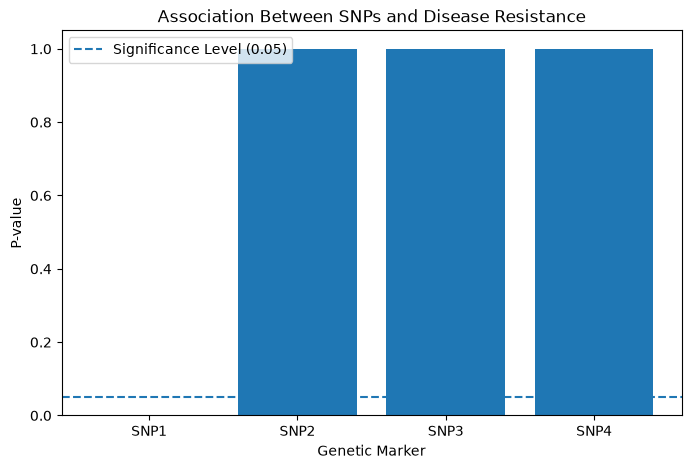

Aditya Rade   BEAD23167


In [8]:
plt.figure(figsize=(8, 5))

plt.bar(results_df['SNP'], results_df['P_Value'])

plt.axhline(
    y=0.05,
    linestyle='--',
    label='Significance Level (0.05)'
)

plt.xlabel("Genetic Marker")
plt.ylabel("P-value")
plt.title("Association Between SNPs and Disease Resistance")
plt.legend()

plt.show()
print("Aditya Rade   BEAD23167")

In [9]:
strongest_marker = results_df.loc[
    results_df['P_Value'].idxmin()
]

print("\nStrongest Associated Genetic Marker:")
print("SNP:", strongest_marker['SNP'])
print("P-value:", strongest_marker['P_Value'])
print("Chi-square value:", strongest_marker['Chi_Square'])


Strongest Associated Genetic Marker:
SNP: SNP1
P-value: 0.0004652581580710503
Chi-square value: 12.25
